# 01 - Données : Morbihan (56)

Chargement des fichiers INSEE (et des décès par âge Eurostat), filtre sur le Morbihan, mise au format long `annee | sexe | tranche_age | effectif`, contrôles de qualité, pyramide des âges 2026.

**Structure des fichiers (vérifiée feuille par feuille, 1975-2026)**

| Fichier | Contenu | Particularités |
|---|---|---|
| `estim-pop-dep-sexe-aq` | pop. 1er janv., sexe × 20 tranches quinquennales | code dép. en col. A ; ordre Ensemble/Hommes/Femmes ; feuille « À savoir » |
| `estim-pop-dep-sexe-gca` | pop. 1er janv., sexe × 5 grandes classes | même mise en page que `aq` |
| `2_Pop1janv` (DEP2) | pop. 1er janv., sexe × 6 groupes | nom en col. A, code 5356 ; ordre **Ensemble/Femmes/Hommes** ; colonne « 15-49 ans (a) » chez les femmes (exclue, elle chevauche) |
| `1_Pop_annu` (DEP1) | population, naissances, décès, soldes | pas d'âge ; « (p) » dans les en-têtes 2023-2024 |
| `3_Naissances` (DEP3), `4_Deces` (DEP4) | naissances, ICF ; décès, espérance de vie | pas d'âge |
| Eurostat `demo_r_magec3` (FRH04) | décès par sexe × tranche quinquennale, 2013-2024 | dernière tranche 90+ |

Les fichiers 5 (mortalité infantile), 6 et 7 (mariages) ne sont pas utilisés : ils ne servent pas à la projection par âge.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from src.chargement import charger_tout
from src.qualite import rapport, coherence_entre_fichiers
from src.graphiques import pyramide

# 1re exécution : lit les Excel (plusieurs minutes) et écrit data/processed/*.csv
# ensuite : relit les CSV. Mettre RELIRE_EXCEL = True après modification des fichiers sources.
RELIRE_EXCEL = False
tables = charger_tout(cache=not RELIRE_EXCEL)
for nom, df in tables.items():
    print(f'{nom:10s} {df.shape}  {df.annee.min()}-{df.annee.max()}')

pop_aq     (3120, 4)  1975-2026
pop_gca    (780, 4)  1975-2026
pop_dep2   (936, 4)  1975-2026
dep1       (255, 5)  1975-2025
dep3       (102, 5)  1975-2025
dep4       (153, 5)  1975-2025
deces_age  (684, 4)  2013-2024


In [2]:
tables['pop_aq'].head()

,annee,sexe,tranche_age,effectif
0,1975,Ensemble,0-4,47355
1,1975,Ensemble,5-9,47990
2,1975,Ensemble,10-14,50486
3,1975,Ensemble,15-19,48453
4,1975,Ensemble,20-24,41001


## Contrôles de qualité

- valeurs manquantes / négatives, grille complète ;
- mêmes tranches d'âge pour toutes les années et tous les sexes, découpages larges compatibles avec le quinquennal ;
- Hommes + Femmes = Ensemble, somme des tranches = Total ;
- totaux par année et tranches regroupées identiques entre fichiers (tolérance 0,5 %) ;
- naissances et décès DEP1 = DEP3/DEP4, P(t) + variation = P(t+1), décès Eurostat ≈ INSEE.

In [3]:
qc = rapport(tables)
print('Contrôles en écart :', (qc.statut != 'OK').sum(), '/', len(qc))
qc

Contrôles en écart : 0 / 29


,controle,table,detail,ecart_max,statut
0,valeurs manquantes / négatives / grille,pop_aq,"0 NA, 0 négatifs, grille complète",0.000000,OK
1,valeurs manquantes / négatives / grille,pop_gca,"0 NA, 0 négatifs, grille complète",0.000000,OK
2,valeurs manquantes / négatives / grille,pop_dep2,"0 NA, 0 négatifs, grille complète",0.000000,OK
3,valeurs manquantes / négatives / grille,dep1,"0 NA, 0 négatifs, grille complète",0.000000,OK
4,valeurs manquantes / négatives / grille,dep3,"0 NA, 0 négatifs, grille complète",0.000000,OK
5,valeurs manquantes / négatives / grille,dep4,"0 NA, 0 négatifs, grille complète",0.000000,OK
6,valeurs manquantes / négatives / grille,deces_age,"0 NA, 0 négatifs, grille complète",0.000000,OK
7,tranches identiques entre années et sexes,pop_aq,0-4 | 5-9 | 10-14 | 15-19 | 20-24 | 25-29 | 30-34 | 35-39 | 40-44 | 45-49 | 50-54 | 55-59 | 60-64 | 65-69 | 70-74 | ...,0.000000,OK
8,tranches identiques entre années et sexes,pop_gca,0-19 | 20-39 | 40-59 | 60-74 | 75+,0.000000,OK
9,tranches identiques entre années et sexes,pop_dep2,0-14 | 15-19 | 20-59 | 60-64 | 65-74 | 75+,0.000000,OK


In [4]:
_, comp = coherence_entre_fichiers(tables)
comp.tail(8)

,estim_aq,estim_gca,dep2,dep1
annee,,,,
2019,759684,759684,759684,759684.0
2020,764161,764161,764161,764161.0
2021,768687,768687,768687,768687.0
2022,776103,776103,776103,776103.0
2023,783390,783390,783390,783390.0
2024,788761,788761,788761,788761.0
2025,793757,793757,793757,793757.0
2026,798958,798958,798958,NaN


## Pyramide des âges 2026

« Jeunes » = 15-29 ans (paramètre `TRANCHES_JEUNES` dans `src/graphiques.py`).

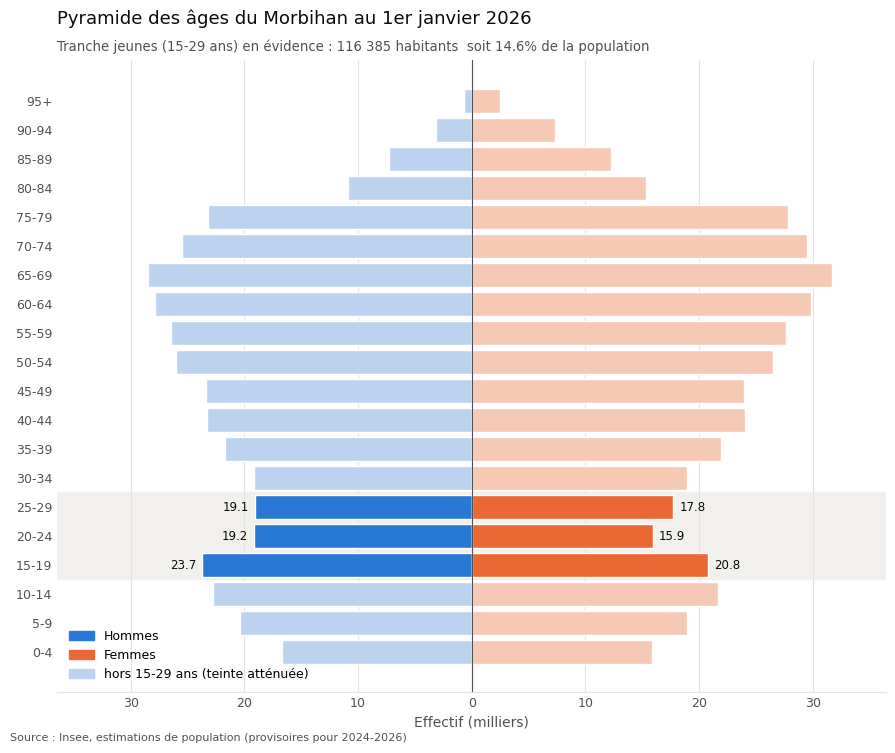

In [5]:
fig, ax = pyramide(tables['pop_aq'], 2026)
fig.savefig('../figures/pyramide_morbihan_2026.png', dpi=150, bbox_inches='tight')